# Entropy - a small example

Scratch notebook to get a feel for entropy. Definitions follow MacKay,
*Information Theory, Inference, and Learning Algorithms*, section 2.4.

Two things get defined there:

The **Shannon information content** of a single outcome $x$ (eq. 2.34):

$$h(x) = \log_2 \frac{1}{P(x)}$$

The **entropy** of the whole ensemble $X$, which is just the average of
$h(x)$ over the distribution (eq. 2.35):

$$H(X) = \sum_{x} P(x) \log_2 \frac{1}{P(x)}$$

Both are measured in bits. The idea is that a rare outcome carries more
information than a common one, and entropy is how much information you
get on average from one draw.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def info_content(p):
    """Shannon information content in bits, eq. 2.34."""
    return np.log2(1 / p)


def entropy(p):
    """Entropy of a distribution in bits, eq. 2.35.

    MacKay's convention is 0 * log(1/0) = 0, so zero-probability
    outcomes just get dropped.
    """
    p = np.asarray(p, dtype=float)
    p = p[p > 0]
    return np.sum(p * np.log2(1 / p))

## A bent coin

Start with the smallest thing that isn't trivial: a coin that comes up
heads 10% of the time.

In [3]:
p_heads = 0.1
coin = np.array([p_heads, 1 - p_heads])

for name, p in zip(["heads", "tails"], coin):
    print(f"{name}: P = {p:.2f}, information content = {info_content(p):.2f} bits")

print(f"\nentropy = {entropy(coin):.4f} bits")

heads: P = 0.10, information content = 3.32 bits
tails: P = 0.90, information content = 0.15 bits

entropy = 0.4690 bits


Heads is the surprising outcome, so it carries 3.32 bits while tails only
carries 0.15. But heads almost never happens, so the average comes out
low - about 0.47 bits per flip. That's well under the 1 bit you'd get
from a fair coin.

Worth checking the two edge cases from the properties listed after
eq. 2.36: entropy is zero when one outcome is certain, and it is largest
when the distribution is uniform.

In [4]:
print(f"certain coin  p = [1, 0]:     H = {entropy([1.0, 0.0]):.4f} bits")
print(f"fair coin     p = [0.5, 0.5]: H = {entropy([0.5, 0.5]):.4f} bits")

certain coin  p = [1, 0]:     H = 0.0000 bits
fair coin     p = [0.5, 0.5]: H = 1.0000 bits


## Sweeping the bias

Since a coin only has one free parameter, the whole picture fits on one
plot. This is the binary entropy function $H_2(p)$ from figure 1.3.

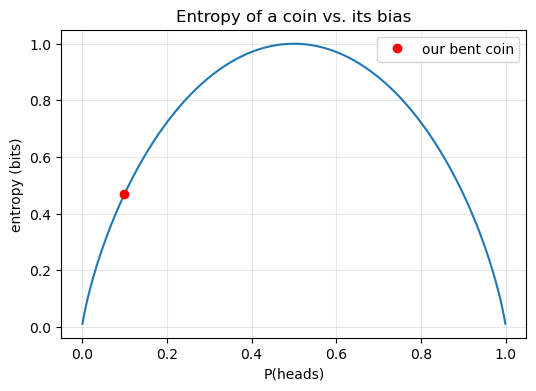

In [5]:
ps = np.linspace(0.001, 0.999, 400)
hs = [entropy([p, 1 - p]) for p in ps]

plt.figure(figsize=(6, 4))
plt.plot(ps, hs)
plt.plot(p_heads, entropy(coin), "o", color="red", label="our bent coin")
plt.xlabel("P(heads)")
plt.ylabel("entropy (bits)")
plt.title("Entropy of a coin vs. its bias")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The curve peaks at p = 0.5 and falls off to zero at both ends. A coin you
can predict tells you nothing when you flip it.

## Checking against the book

MacKay's example 2.12 says a letter picked at random from English text
has an entropy of about 4.11 bits, using the frequencies in table 2.9.
Good chance to check that the function above is right.

In [6]:
# letter frequencies from table 2.9 ('-' is the space character)
letters = "abcdefghijklmnopqrstuvwxyz-"
freqs = np.array([
    .0575, .0128, .0263, .0285, .0913, .0173, .0133, .0313, .0599,
    .0006, .0084, .0335, .0235, .0596, .0689, .0192, .0008, .0508,
    .0567, .0706, .0334, .0069, .0119, .0073, .0164, .0007, .1928,
])

print(f"probabilities sum to {freqs.sum():.4f}")
print(f"H(X) = {entropy(freqs):.2f} bits  (book says about 4.11)")

probabilities sum to 1.0002
H(X) = 4.11 bits  (book says about 4.11)


In [7]:
# most and least informative letters
order = np.argsort(freqs)
print("rarest (most information):")
for i in order[:3]:
    print(f"  {letters[i]}: P = {freqs[i]:.4f}, h = {info_content(freqs[i]):.1f} bits")
print("most common (least information):")
for i in order[-3:]:
    print(f"  {letters[i]}: P = {freqs[i]:.4f}, h = {info_content(freqs[i]):.1f} bits")

rarest (most information):
  j: P = 0.0006, h = 10.7 bits
  z: P = 0.0007, h = 10.5 bits
  q: P = 0.0008, h = 10.3 bits
most common (least information):
  t: P = 0.0706, h = 3.8 bits
  e: P = 0.0913, h = 3.5 bits
  -: P = 0.1928, h = 2.4 bits


Matches. Note that no single letter has an information content of 4.11
bits - `z` carries 10.5 and a space carries only 2.4. The entropy is the
average, not a typical value.

One last thing: with 27 possible characters, the most entropy you could
possibly have is $\log_2 27$, which happens if every letter is equally
likely. The gap between that and the real value is what MacKay calls
redundancy (eq. 2.37).

In [8]:
h_max = np.log2(len(letters))
h_actual = entropy(freqs)

print(f"maximum possible: {h_max:.2f} bits")
print(f"actual:           {h_actual:.2f} bits")
print(f"redundancy:       {1 - h_actual / h_max:.1%}")

maximum possible: 4.75 bits
actual:           4.11 bits
redundancy:       13.6%


So English letter frequencies waste about 13% of the capacity you'd have
if all 27 characters were equally likely. That is the slack a compression
scheme gets to take advantage of, which is where chapters 4 and 5 go.